## Student Performance Indicator


#### Life cycle of ML Project

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis(EDA)
- Data Pre-Processing
- Model Training
- Choose best model(or use pycaret which selects the best one automatically) 

### 1) Problem statement

- The challenge is to predict student's test scores on the basis of features such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.

### 2) Data Source
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

### 2.1 Import Data and Required Packages

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
# import warnings
# warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('data/stud.csv')

In [3]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
df.describe() # provides a brief summary of mathematical(statical) information
              # used for outlier detection and filling null places

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


#### Insight
- Mean and Std of all the numerical columns are almost within the same range. Hence need for standardization is low.
- Minimum score for math is 0 and is above or equal to 10 for others 
- There is no negative or unexpected high values.
- Value of mean and median is almost similar which shows that data is normally distributed(bell-shaped). No skewness
- Count is the same as the number of records shows that there are no null values in the numeric(continuous) part of dataset 

In [ ]:
df.describe(include='all') ## Pandas ignores non-numeric columns by default unless you explicitly mention.

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


In [ ]:
df.info() # Check Null and Dtypes

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [4]:
df.shape

(1000, 8)

### 2.2 Dataset information

- gender : sex of students  -> (Male/female)
- race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)
- parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)
- lunch : having lunch before test (standard or free/reduced) 
- test preparation course : complete or not complete before test
- math score
- reading score
- writing score

### 3. Data Checks to perform

- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set
- Check various categories present in the different categorical column

### 3.1 Check Missing values

In [ ]:
df.isna().sum()  ## No missing values

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

### 3.2 Check Duplicates

In [10]:
df.duplicated().sum()  ## NO duplicate values 

np.int64(0)

### 3.4 Checking the number of unique values of each column

In [12]:
df.nunique() ## What nunique does for the entire dataframe, values_count does that... 
             ## ...for a specific column by mapping it witht the actual number of count.

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

### 3.7 Exploring Data

In [18]:
print("Categories in 'gender' variable:",end="")
print(df['gender'].unique().tolist())

print("Categories in 'race_ethnicity' variable:",end="")
print(df['race_ethnicity'].unique().tolist())

print("Categories in'parental level of education' variable:",end="")
print(df['parental_level_of_education'].unique().tolist())

print("Categories in 'lunch' variable:",end="")
print(df['lunch'].unique().tolist())

print("Categories in 'test preparation course' variable:",end="")
print(df['test_preparation_course'].unique().tolist())

Categories in 'gender' variable:['female', 'male']
Categories in 'race_ethnicity' variable:['group B', 'group C', 'group A', 'group D', 'group E']
Categories in'parental level of education' variable:["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
Categories in 'lunch' variable:['standard', 'free/reduced']
Categories in 'test preparation course' variable:['none', 'completed']


In [31]:
print(df.select_dtypes(include='object'))

     gender race_ethnicity parental_level_of_education         lunch  \
0    female        group B           bachelor's degree      standard   
1    female        group C                some college      standard   
2    female        group B             master's degree      standard   
3      male        group A          associate's degree  free/reduced   
4      male        group C                some college      standard   
..      ...            ...                         ...           ...   
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test_preparation_course  
0                      none  
1                 completed  
2                      none  
3              

C:\Users\Admin\AppData\Local\Temp\ipykernel_30508\3472710906.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include='object'))


In [36]:
# Identify numerical & categorical columns
numeric_features = df.select_dtypes(include=['number']).columns.tolist()
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('We have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 3 numerical features : ['math_score', 'reading_score', 'writing_score']
We have 5 categorical features : ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


C:\Users\Admin\AppData\Local\Temp\ipykernel_30508\714394148.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns.tolist()


### 3.8 Creating new columns for "Total Score" and "Average"

In [38]:
df['total score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = (df['total score']/3).round(2)
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.67
1,female,group C,some college,standard,completed,69,90,88,247,82.33
2,female,group B,master's degree,standard,none,90,95,93,278,92.67
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.33
4,male,group C,some college,standard,none,76,78,75,229,76.33


### Number of students with full marks

In [40]:
reading_full = len(df[df['reading_score'] == 100])
writing_full = len(df[df['writing_score'] == 100])
math_full = len(df[df['math_score'] == 100])

print(f'Maths: {math_full}')
print(f'Writing: {writing_full}')
print(f'Reading: {reading_full}')

Maths: 7
Writing: 14
Reading: 17


### Number of students who likely failed(below 33) 

In [41]:
reading_less_20 = len(df[df['reading_score'] < 33])
writing_less_20 = len(df[df['writing_score'] < 33])
math_less_20 = len(df[df['math_score'] < 33])

print(f'Maths: {math_less_20}')
print(f'Writing: {writing_less_20}')
print(f'Reading: {reading_less_20}')

Maths: 19
Writing: 12
Reading: 11


### 4. Data Visualization 
#### 4.1 Visualize average score distribution to draw out some conclusions. 
- Histogram
- Kernel Distribution Function (KDE)

#### 4.1.1 Histogram & KDE
##### Histogram : A univariate chart(uses only one numerical feature),Basically it analyzes the a single numerical feature with data points clustered in bin against the frequency
##### KDE : A KDE is the summation of all those tiny individual bell curves (kernels) centered on every single data point.

In [48]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total score', 'average'],
      dtype='str')

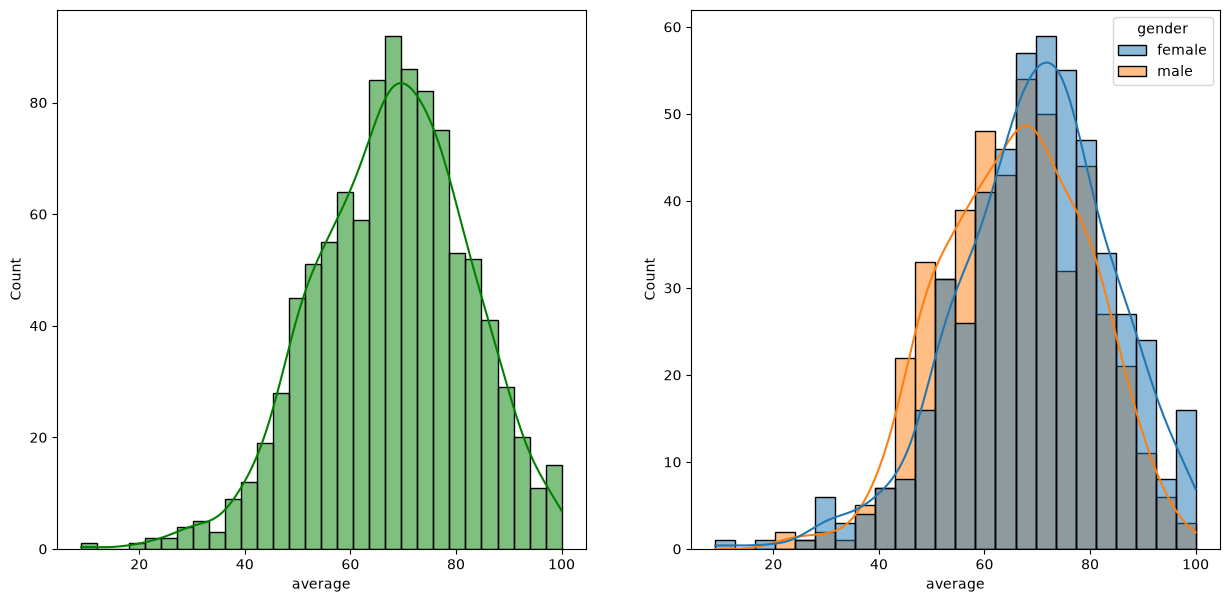

In [50]:
plt.subplots(1, 2, figsize=(15, 7))  ## First histogram is giving an analysis of average column and second is category specific analysis      
plt.subplot(121)
sns.histplot(data=df,x='average',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='average',kde=True,hue='gender')
plt.show()

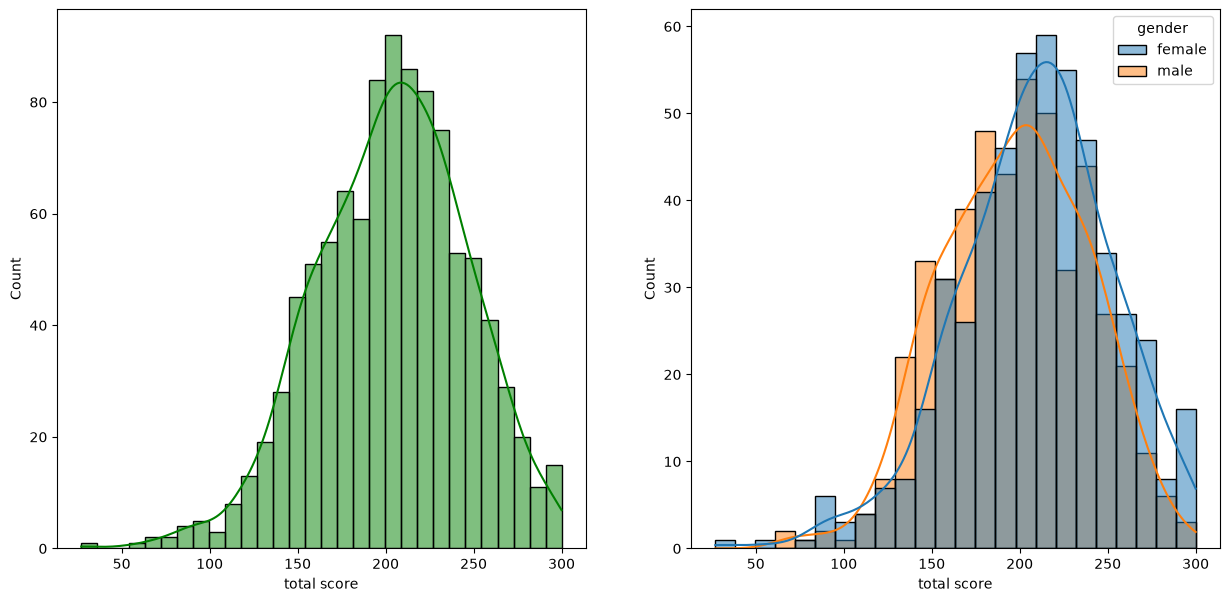

In [45]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df,x='total score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='total score',kde=True,hue='gender')
plt.show()

<Axes: xlabel='average', ylabel='Count'>

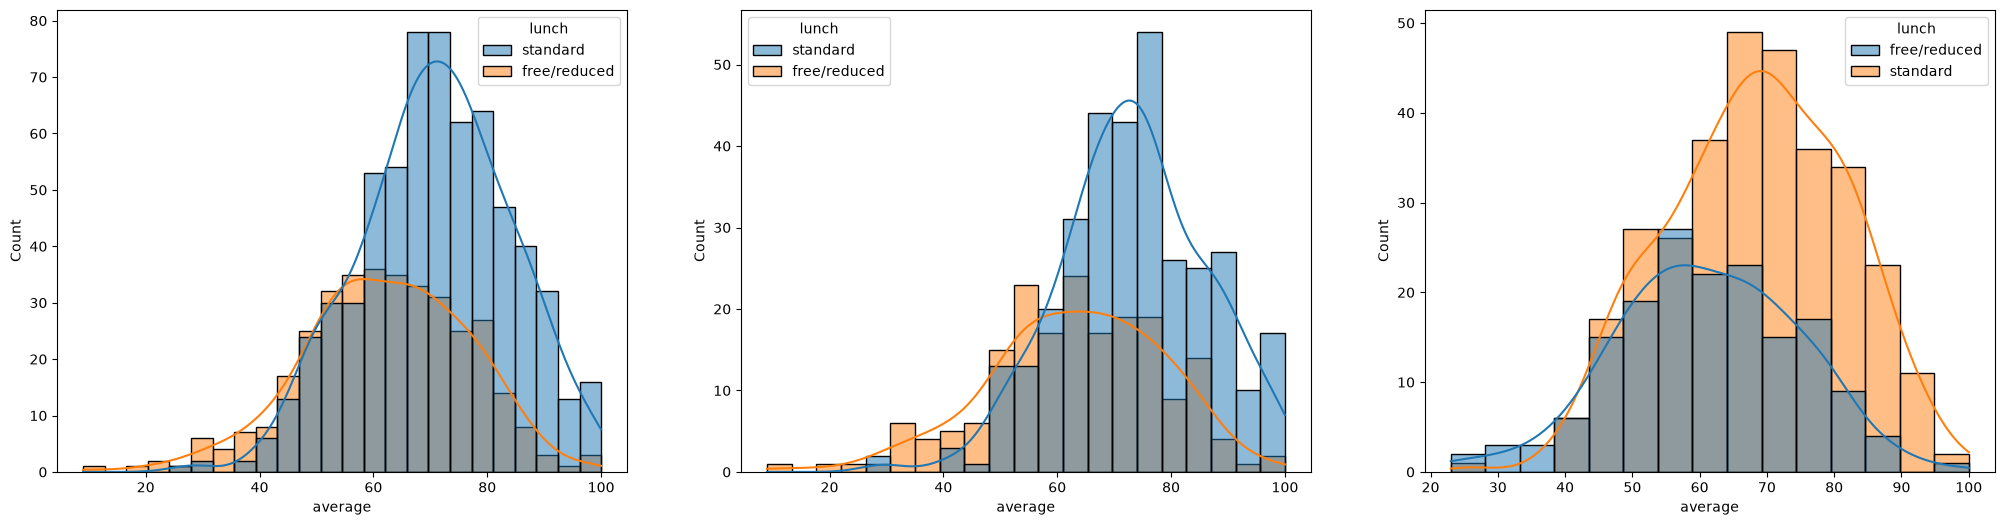

In [51]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(131)                                      
sns.histplot(data=df,x='average',kde=True,hue='lunch')
plt.subplot(132)
sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='lunch')
plt.subplot(133)
sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='lunch')

<Axes: xlabel='average', ylabel='Count'>

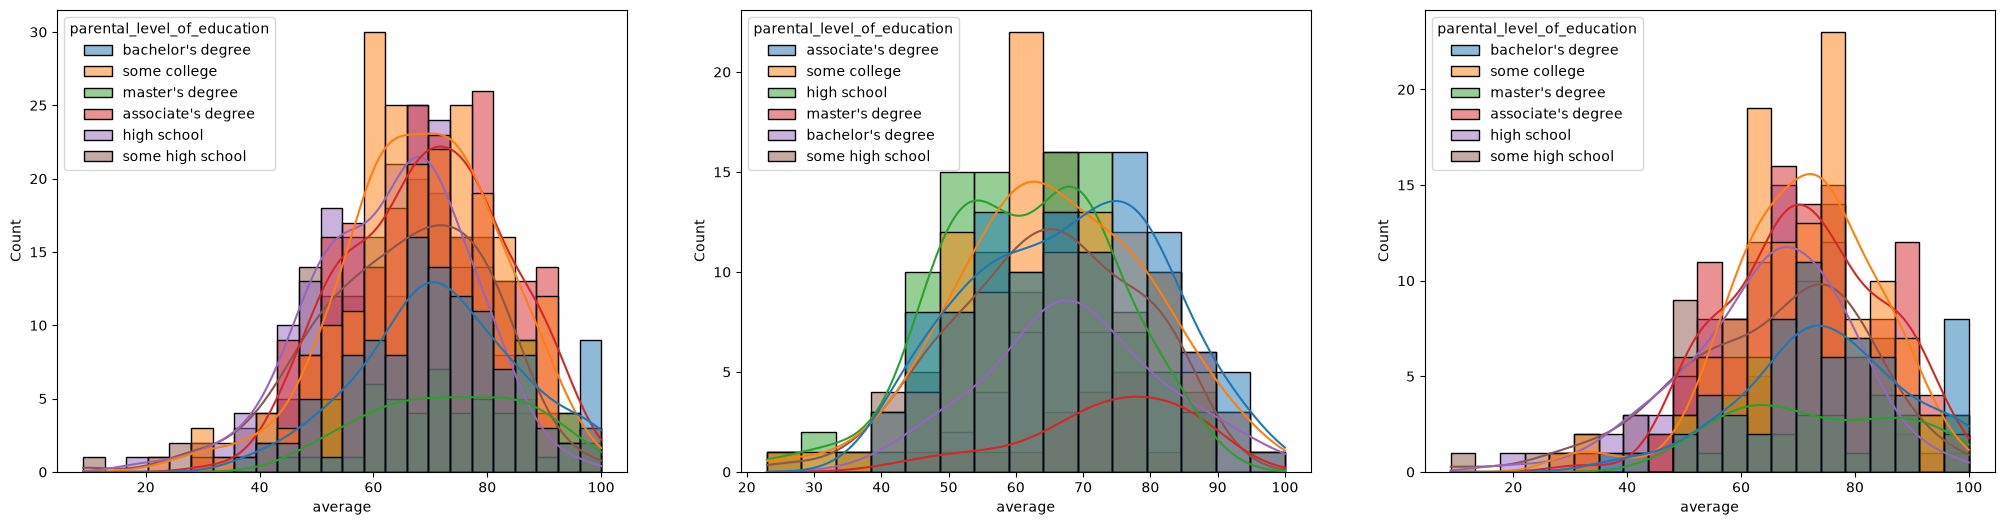

In [53]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(131)
sns.histplot(data=df,x='average',kde=True,hue='parental_level_of_education')
plt.subplot(132)
sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='parental_level_of_education')
plt.subplot(133)
sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='parental_level_of_education')


In [55]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total score', 'average'],
      dtype='str')

<Axes: xlabel='average', ylabel='Count'>

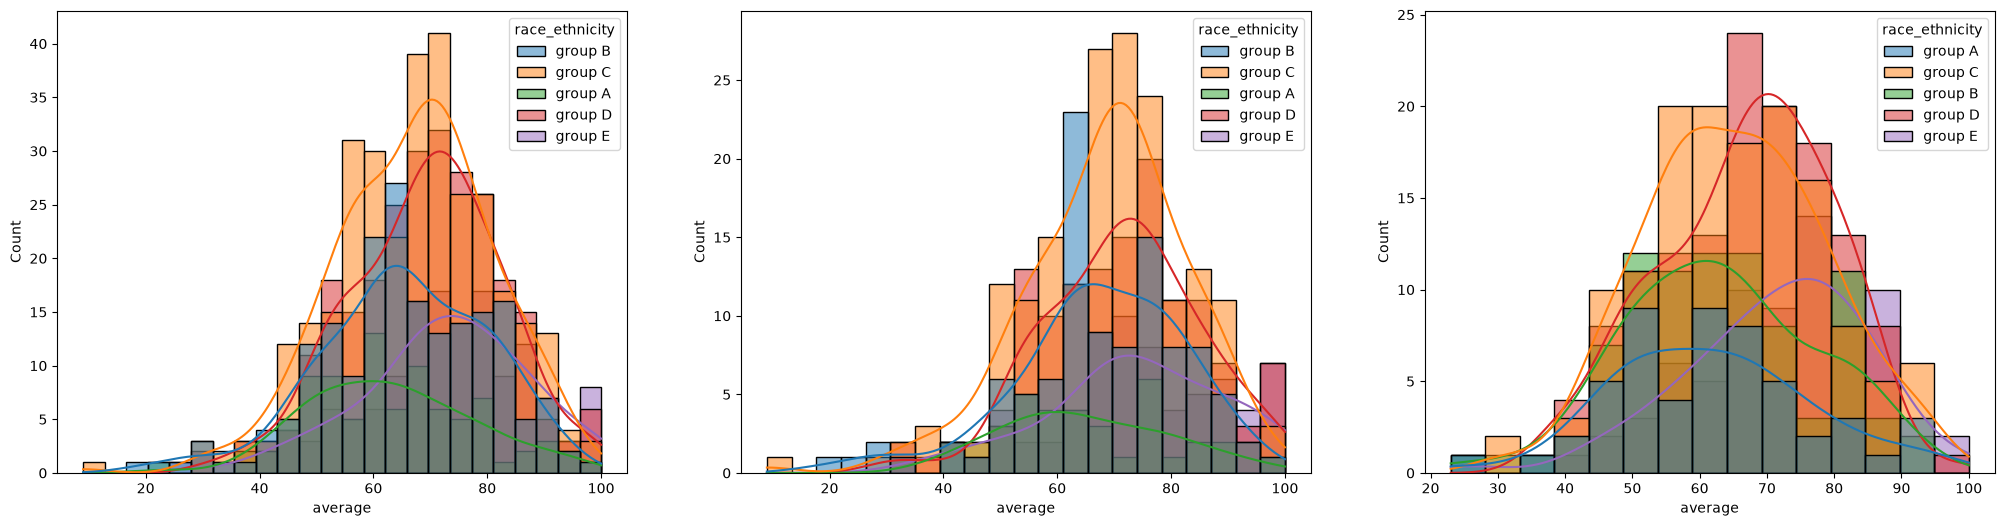

In [56]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(131)
sns.histplot(data=df,x='average',kde=True,hue='race_ethnicity')
plt.subplot(132)
sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='race_ethnicity')
plt.subplot(133)
sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='race_ethnicity')

#####  Insights
- Students of group A, group E and group B tends to perform poorly in exam irrespective of sex.

#### 4.2 Heatmap for correlation of all the features with target 

In [66]:
numeric_features = df.select_dtypes('number')

In [69]:
numeric_features

,math_score,reading_score,writing_score,total score,average
0,72,72,74,218,72.67
1,69,90,88,247,82.33
2,90,95,93,278,92.67
3,47,57,44,148,49.33
4,76,78,75,229,76.33
...,...,...,...,...,...
995,88,99,95,282,94.00
996,62,55,55,172,57.33
997,59,71,65,195,65.00
998,68,78,77,223,74.33


<Axes: >

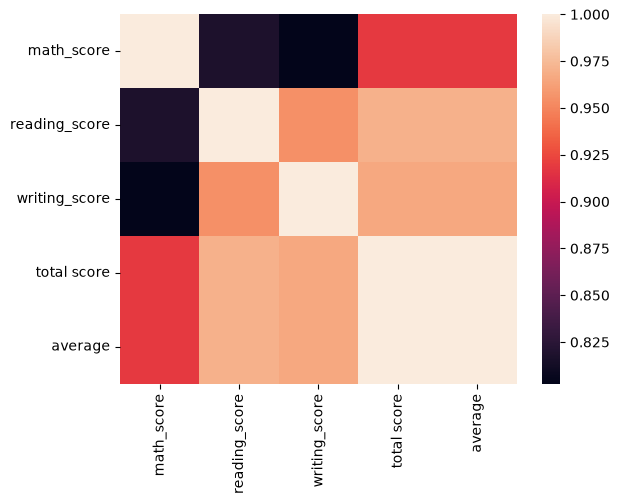

In [71]:
sns.heatmap((numeric_features.corr()))

In [59]:

# plt.figure(figsize=(18,8))
# plt.subplot(1, 4, 1)
# plt.title('MATH SCORES')
# sns.violinplot(y='math_score',data=df,color='red',linewidth=3)
# plt.subplot(1, 4, 2)
# plt.title('READING SCORES')
# sns.violinplot(y='reading_score',data=df,color='green',linewidth=3)
# plt.subplot(1, 4, 3)
# plt.title('WRITING SCORES')
# sns.violinplot(y='writing_score',data=df,color='blue',linewidth=3)
# plt.show()

#### 4.3 Multivariate analysis using pieplot

In [72]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total score', 'average'],
      dtype='str')

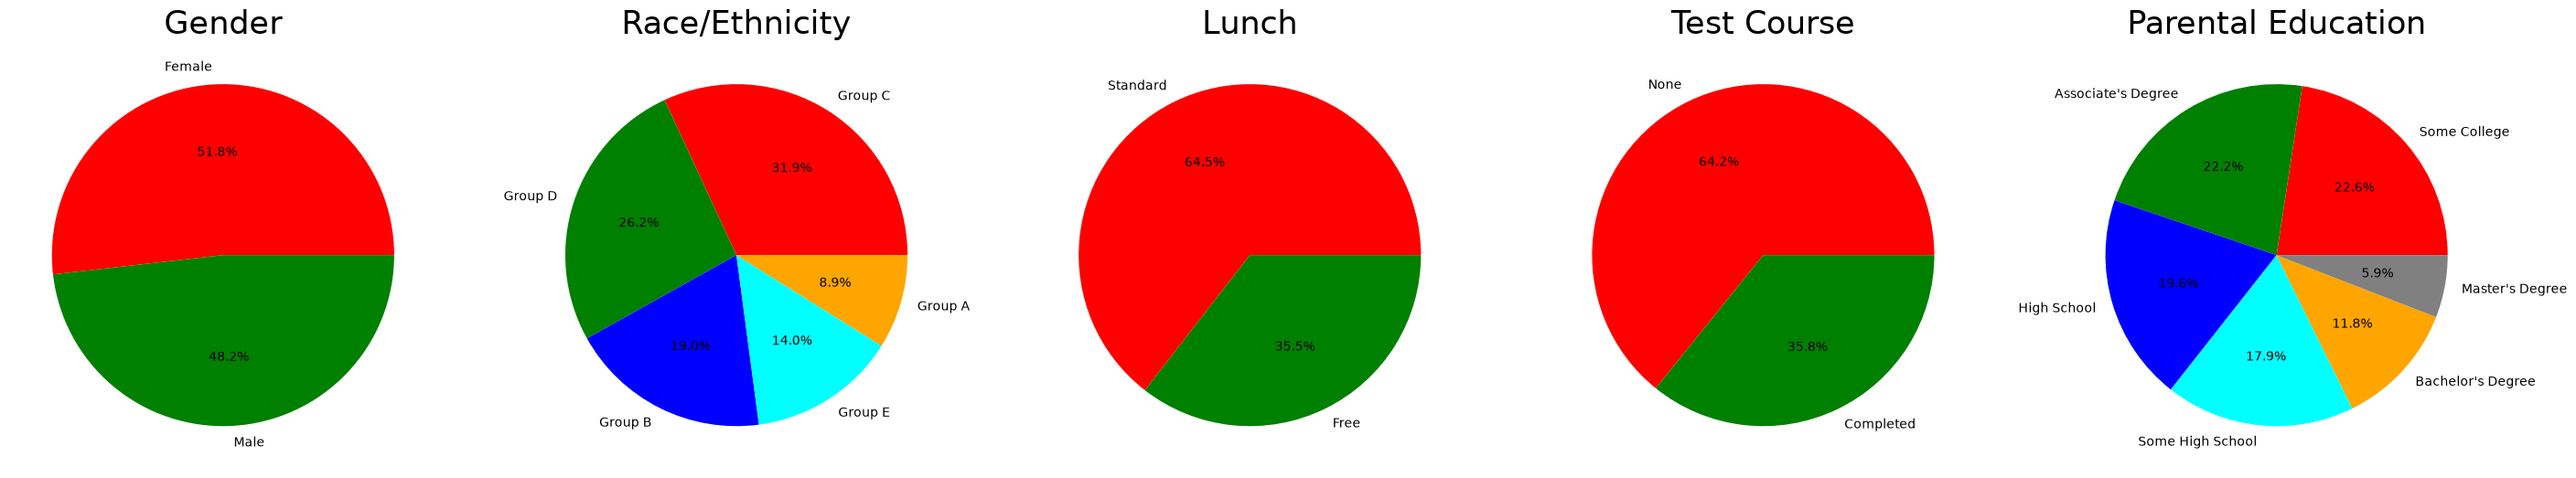

In [85]:
plt.rcParams['figure.figsize'] = (35, 20)

plt.subplot(1, 5, 1)
size = df['gender'].value_counts()
labels = 'Female', 'Male'
color = ['red','green']


plt.pie(size, colors = color, labels = labels,autopct = '%1.1f%%')
plt.title('Gender', fontsize = 25)
plt.axis('off')



plt.subplot(1, 5, 2)
size = df['race_ethnicity'].value_counts()
labels = 'Group C', 'Group D','Group B','Group E','Group A'
color = ['red', 'green', 'blue', 'cyan','orange']

plt.pie(size, colors = color,labels = labels,autopct = '%1.1f%%')
plt.title('Race/Ethnicity', fontsize = 25)
plt.axis('off')



plt.subplot(1, 5, 3)
size = df['lunch'].value_counts()
labels = 'Standard', 'Free'
color = ['red','green']

plt.pie(size, colors = color,labels = labels,autopct = '%1.1f%%')
plt.title('Lunch', fontsize = 25)
plt.axis('off')


plt.subplot(1, 5, 4)
size = df['test_preparation_course'].value_counts()
labels = 'None', 'Completed'
color = ['red','green']

plt.pie(size, colors = color,labels = labels,autopct = '%1.1f%%')
plt.title('Test Course', fontsize = 25)
plt.axis('off')


plt.subplot(1, 5, 5)
size = df['parental_level_of_education'].value_counts()
labels = 'Some College', "Associate's Degree",'High School','Some High School',"Bachelor's Degree","Master's Degree"
color = ['red', 'green', 'blue', 'cyan','orange','grey']

plt.pie(size, colors = color,labels = labels,autopct = '%1.1f%%')
plt.title('Parental Education', fontsize = 25)
plt.axis('off')


# plt.tight_layout()
# plt.grid()

plt.show()

#####  Insights
- Number of Male and Female students is almost equal
- Number students are greatest in Group C
- Number of students who have standard lunch are greater
- Number of students who have not enrolled in any test preparation course is greater
- Number of students whose parental education is "Some College" is greater followed closely by "Associate's Degree"

#### 4.4 Feature Wise Visualization
#### 4.4.1 GENDER COLUMN
- How is distribution of Gender ? Univariate analysis
- Is gender has any impact on student's performance ?  Bivariate analysis

#### UNIVARIATE ANALYSIS ( How is distribution of Gender ? )

C:\Users\Admin\AppData\Local\Temp\ipykernel_30508\1720327845.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['gender'],data=df,palette ='bright',ax=ax[0],saturation=0.95)


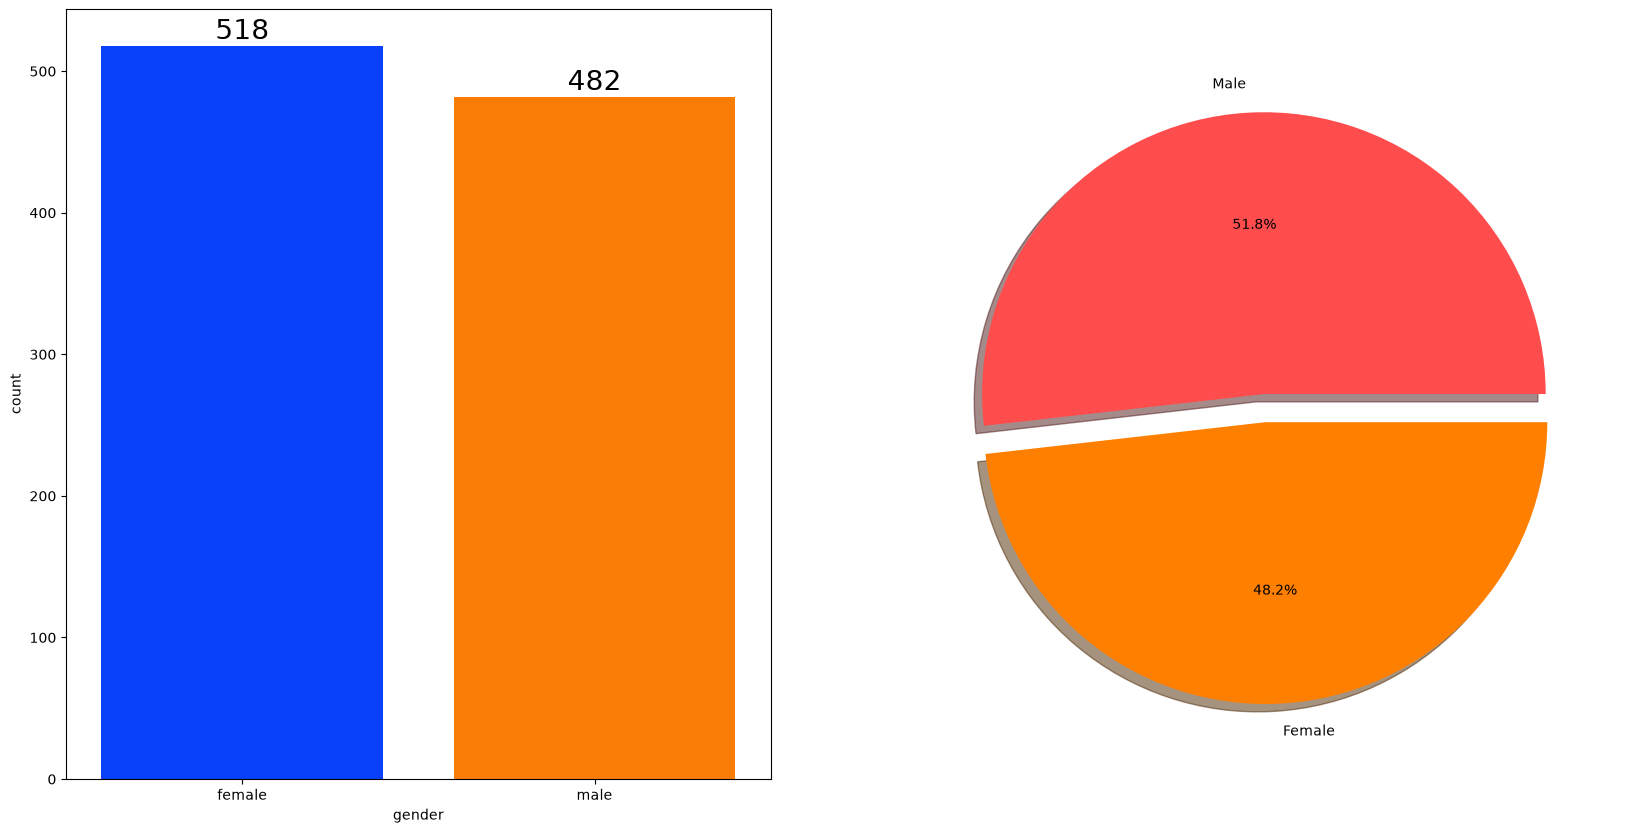

In [86]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['gender'],data=df,palette ='bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x=df['gender'].value_counts(),labels=['Male','Female'],explode=[0,0.1],autopct='%1.1f%%',shadow=True,colors=['#ff4d4d','#ff8000'])
plt.show()

#### Insights 
- Gender has balanced data with female students are 518 (48%) and male students are 482 (52%) 

#### BIVARIATE ANALYSIS ( Is gender has any impact on student's performance ? ) 

In [88]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total score', 'average'],
      dtype='str')

In [100]:
gender_group = df.groupby('gender')['average'].mean()
gender_group


gender
female    69.569498
male      65.837303
Name: average, dtype: float64

In [103]:
math_average = df.groupby('gender')['math_score'].mean()
math_average

gender
female    63.633205
male      68.728216
Name: math_score, dtype: float64

In [106]:
type(math_average)

pandas.Series

In [ ]:
math_average.loc['female'].round(2)
gender_group

np.float64(63.63)

In [ ]:
female_scores = [math_average.loc['female'].round(2), gender_group.loc['female'].round(2)]
male_scores = [math_average.loc['male'].round(2), gender_group.loc['male'].round(2)]

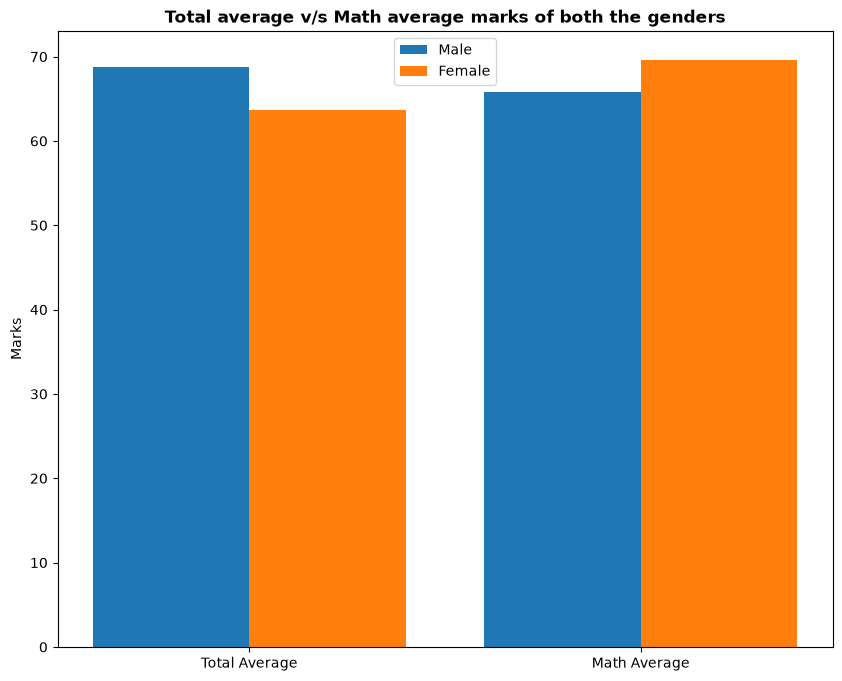

In [113]:
plt.figure(figsize=(10, 8))

X = ['Total Average','Math Average']
X_axis = np.arange(len(X))
  
plt.bar(X_axis - 0.2, male_scores, 0.4, label = 'Male')
plt.bar(X_axis + 0.2, female_scores, 0.4, label = 'Female')
  
plt.xticks(X_axis, X)
plt.ylabel("Marks")
plt.title("Total average v/s Math average marks of both the genders", fontweight='bold')
plt.legend()
plt.show()

#### Insights 
- On an average females have a better overall score than men.
- whereas males have scored higher in Maths.

#### 4.4.2 RACE/EHNICITY COLUMN


C:\Users\Admin\AppData\Local\Temp\ipykernel_30508\2697237789.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['race_ethnicity'],data=df,palette = 'bright',ax=ax[0],saturation=0.95)


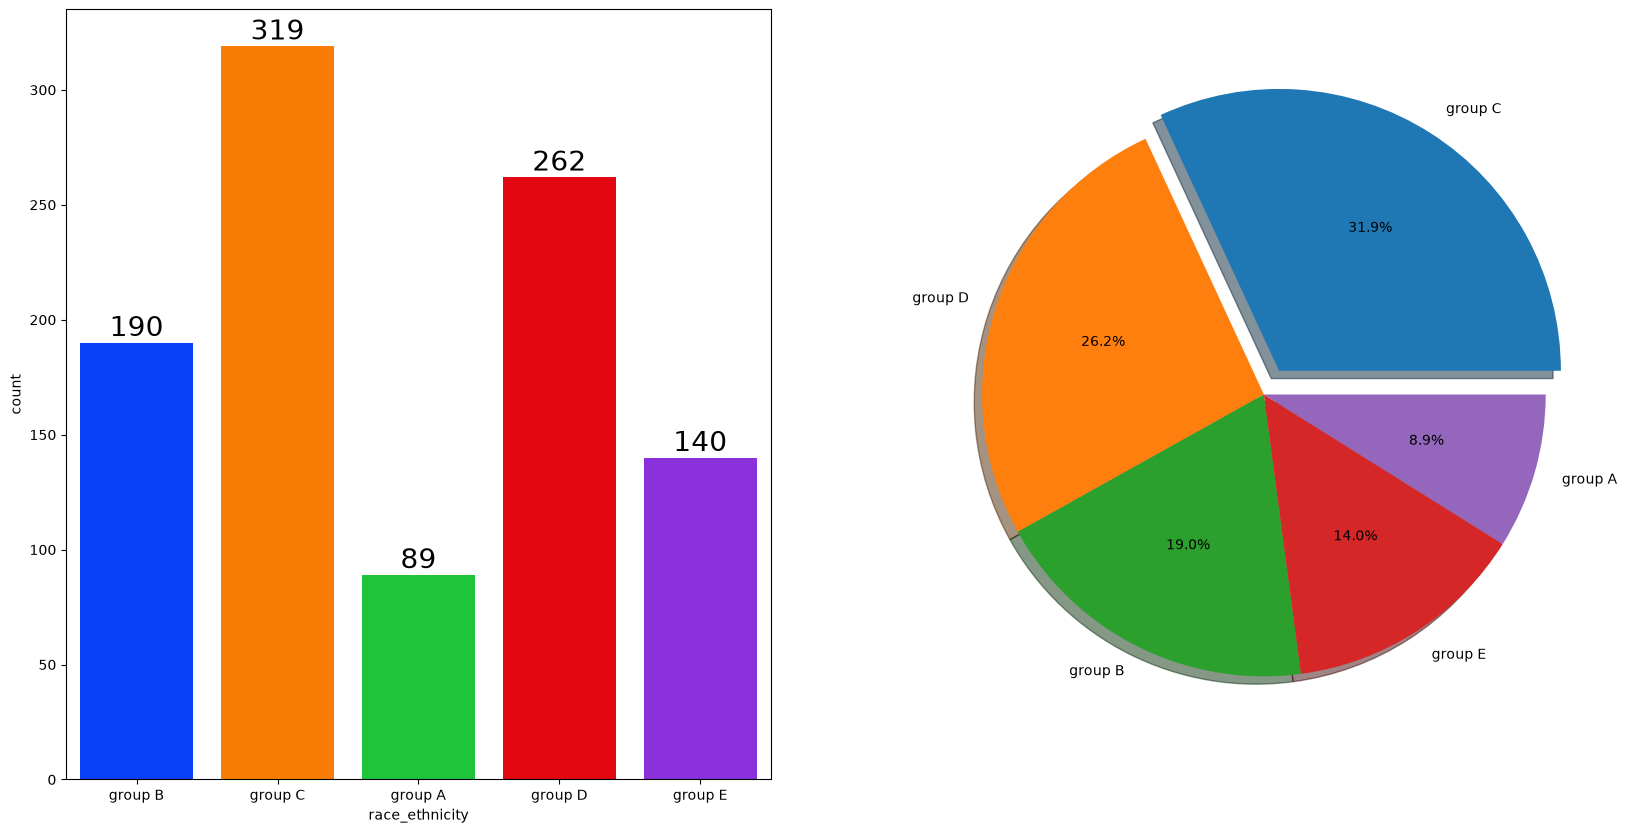

In [115]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['race_ethnicity'],data=df,palette = 'bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x = df['race_ethnicity'].value_counts(),labels=df['race_ethnicity'].value_counts().index,explode=[0.1,0,0,0,0],autopct='%1.1f%%',shadow=True)
plt.show()   

#### Insights 
- Most of the student belonging from group C /group D.
- Lowest number of students belong to groupA.

C:\Users\Admin\AppData\Local\Temp\ipykernel_30508\827462696.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=Group_data2['math_score'].mean().index,y=Group_data2['math_score'].mean().values,palette = 'mako',ax=ax[0])
C:\Users\Admin\AppData\Local\Temp\ipykernel_30508\827462696.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=Group_data2['reading_score'].mean().index,y=Group_data2['reading_score'].mean().values,palette = 'flare',ax=ax[1])
C:\Users\Admin\AppData\Local\Temp\ipykernel_30508\827462696.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect

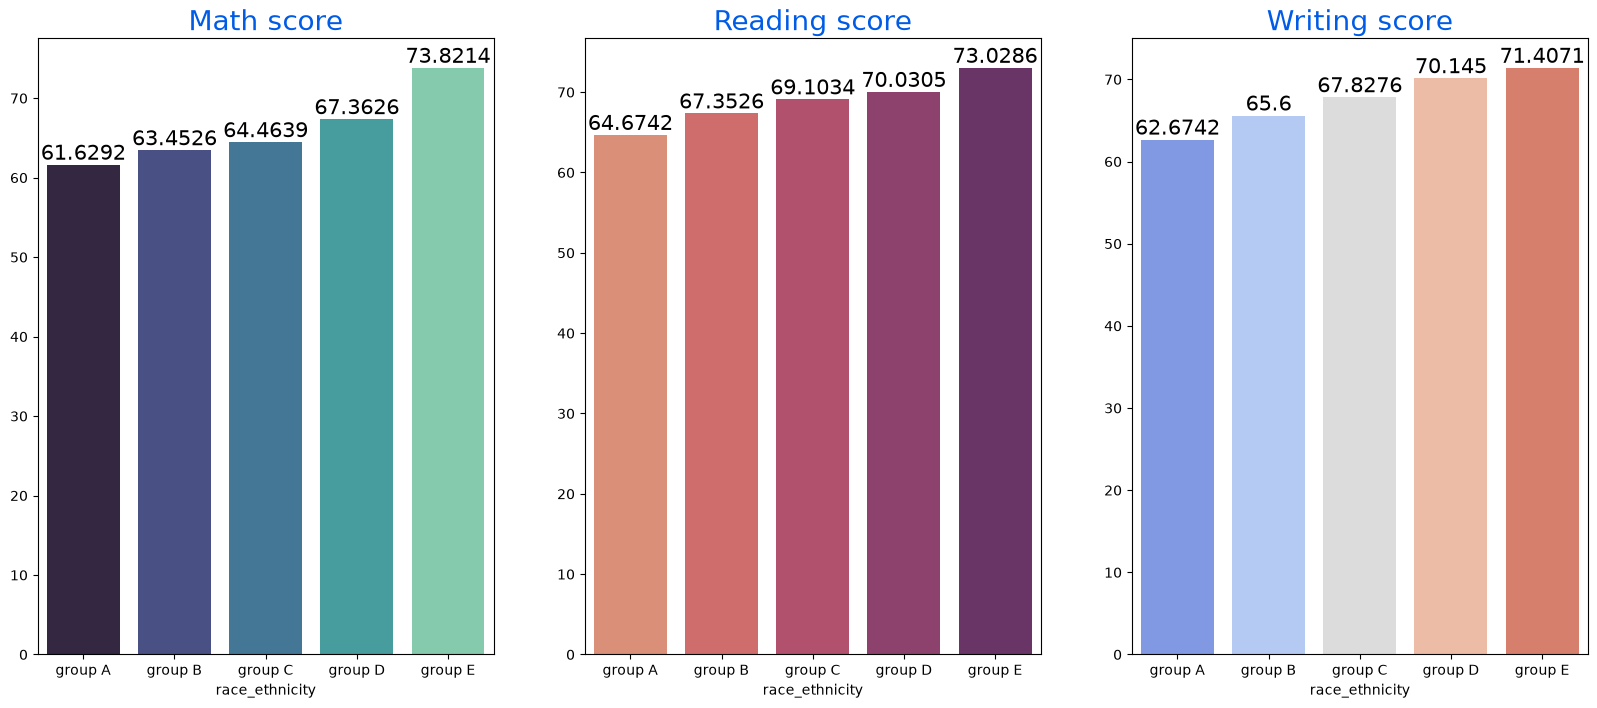

In [117]:
Group_data2=df.groupby('race_ethnicity')
f,ax=plt.subplots(1,3,figsize=(20,8))
sns.barplot(x=Group_data2['math_score'].mean().index,y=Group_data2['math_score'].mean().values,palette = 'mako',ax=ax[0])
ax[0].set_title('Math score',color='#005ce6',size=20)

for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=15)

sns.barplot(x=Group_data2['reading_score'].mean().index,y=Group_data2['reading_score'].mean().values,palette = 'flare',ax=ax[1])
ax[1].set_title('Reading score',color='#005ce6',size=20)

for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=15)

sns.barplot(x=Group_data2['writing_score'].mean().index,y=Group_data2['writing_score'].mean().values,palette = 'coolwarm',ax=ax[2])
ax[2].set_title('Writing score',color='#005ce6',size=20)

for container in ax[2].containers:
    ax[2].bar_label(container,color='black',size=15)

#### 4.4.3 PARENTAL LEVEL OF EDUCATION COLUMN


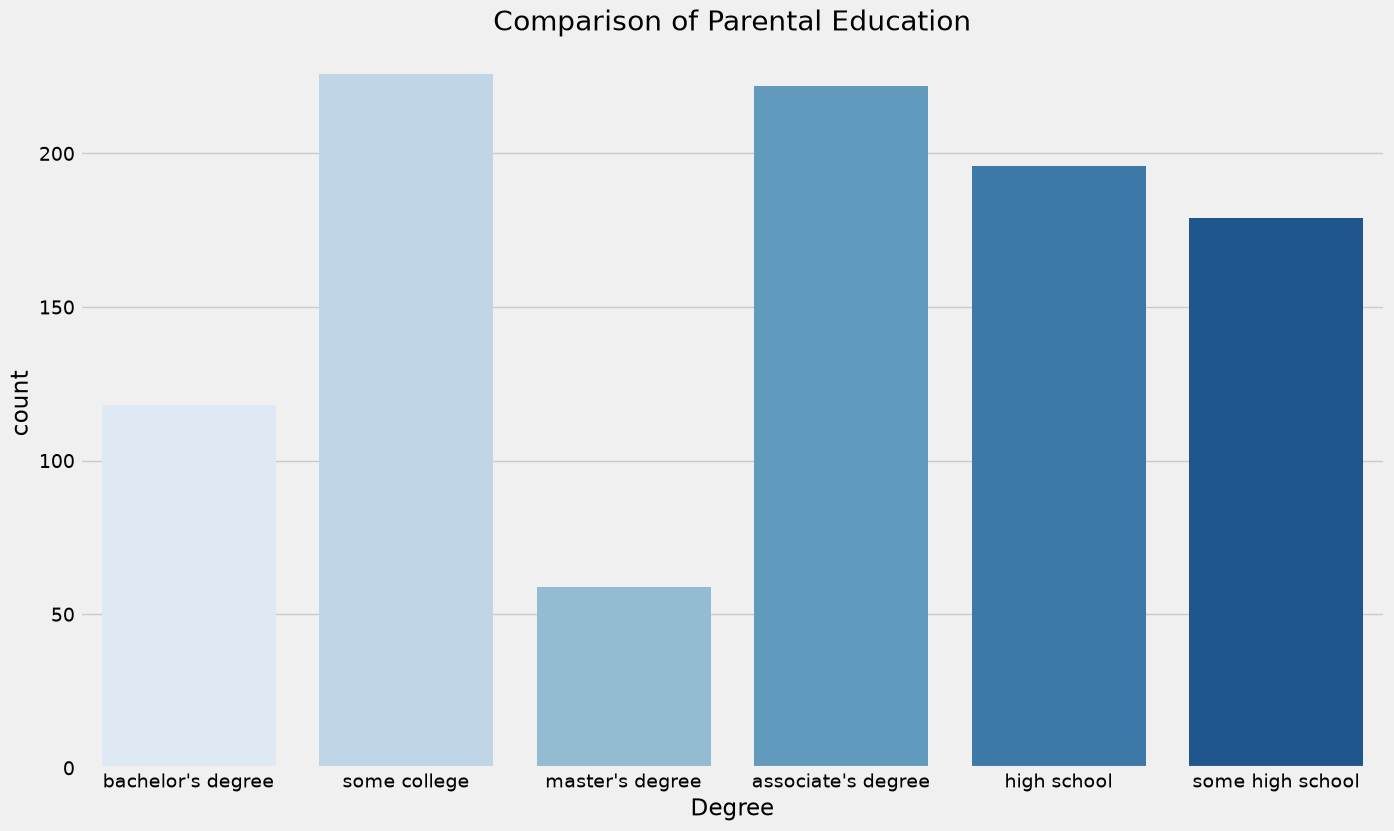

In [123]:
plt.rcParams['figure.figsize'] = (15, 9)
sns.countplot(data=df,x='parental_level_of_education',palette = 'Blues',hue ='parental_level_of_education', legend = False)
plt.title('Comparison of Parental Education')
plt.xlabel('Degree')
plt.ylabel('count')
plt.show()

<Axes: xlabel='Count', ylabel='Degree'>

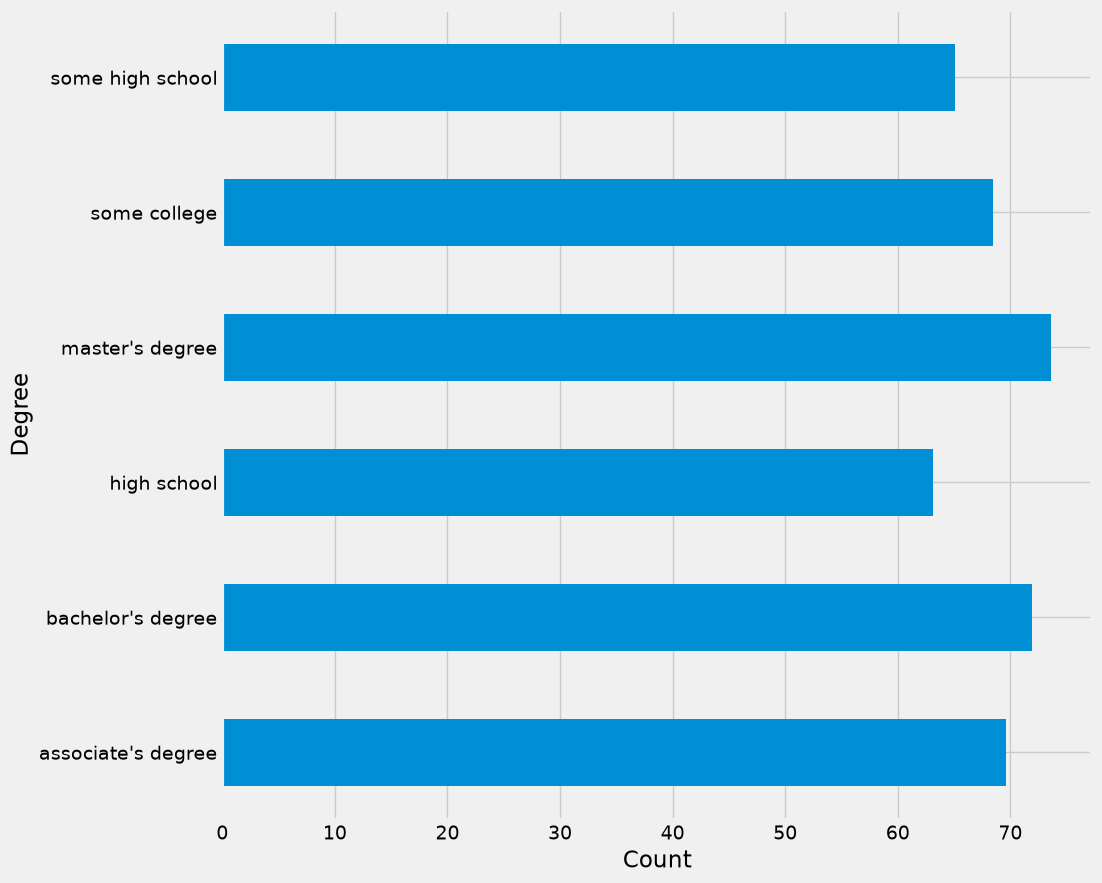

In [128]:
df.groupby('parental_level_of_education')['average'].mean().plot(kind='barh',figsize=(10,10),ylabel='Degree',xlabel='Count')


#### 4.4.4 LUNCH COLUMN 



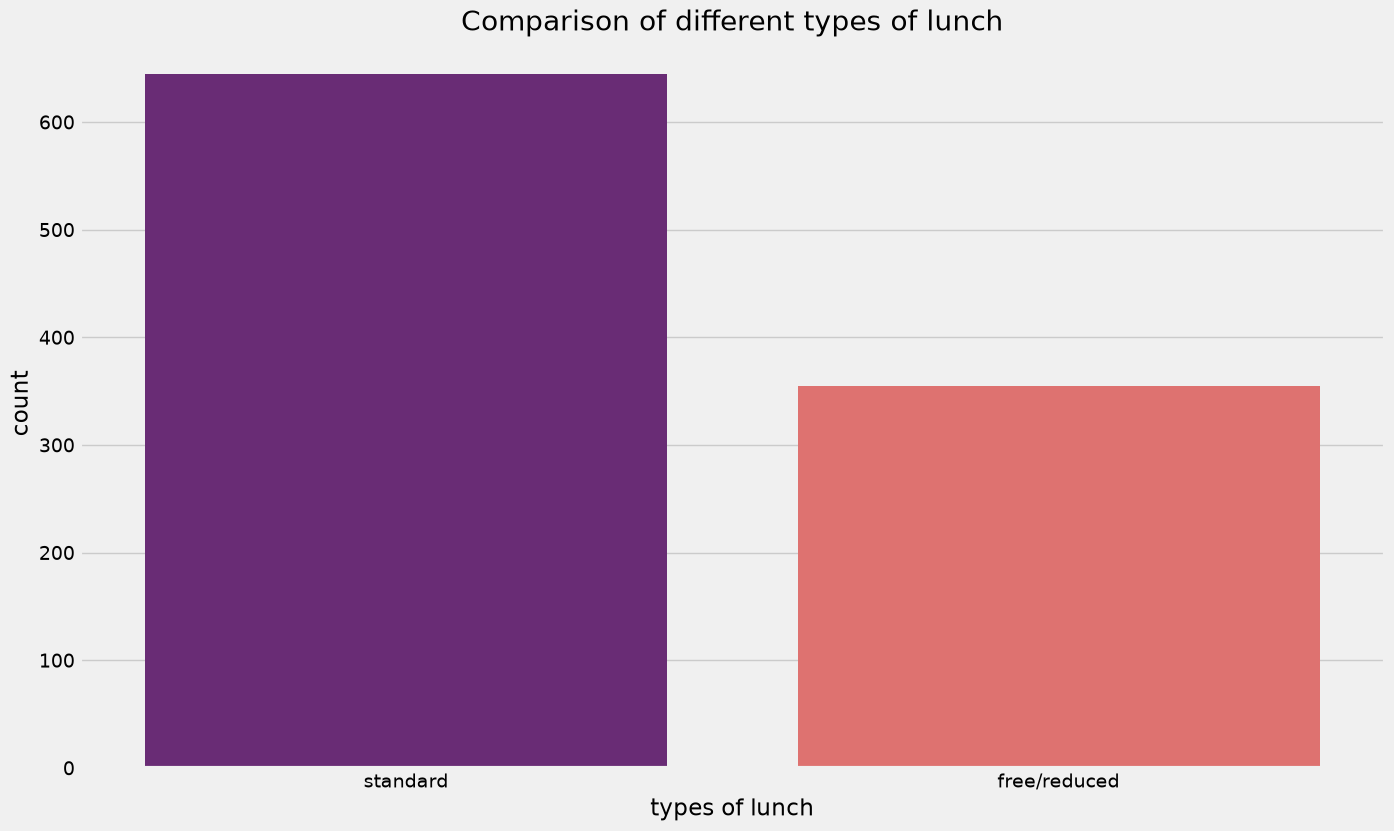

In [130]:
plt.rcParams['figure.figsize'] = (15, 9)
sns.countplot(data = df, x = 'lunch', hue= 'lunch' ,palette = 'magma')
plt.title('Comparison of different types of lunch')
plt.xlabel('types of lunch')
plt.ylabel('count')
plt.show()

In [131]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total score', 'average'],
      dtype='str')

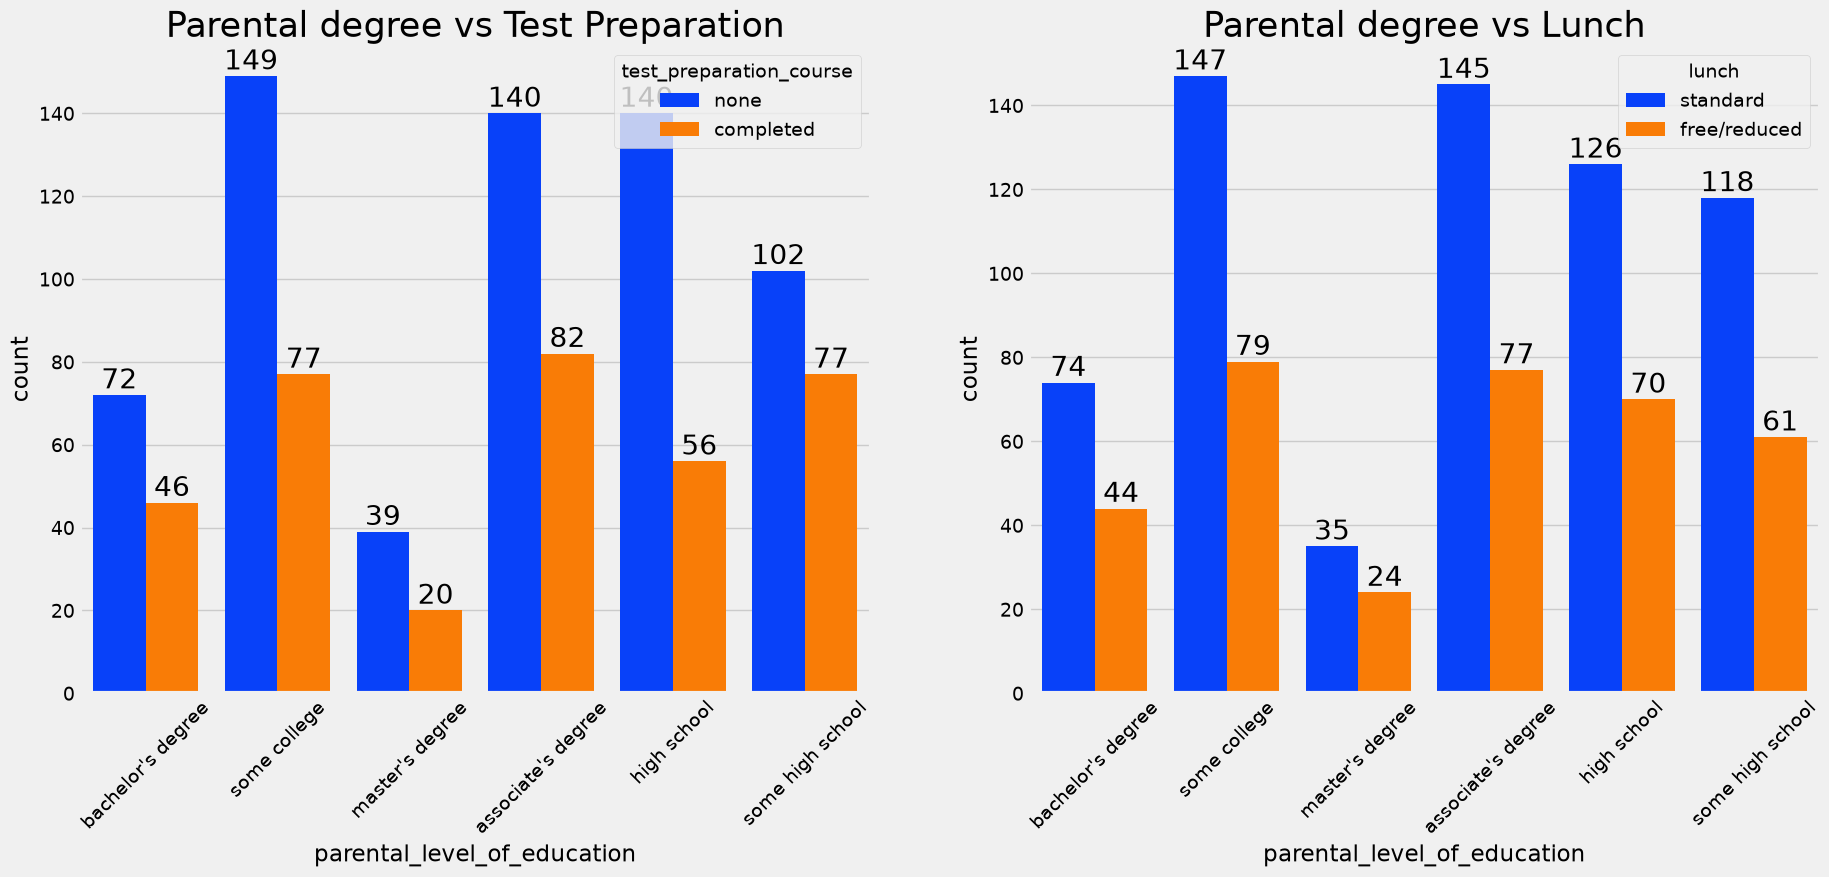

In [136]:
f,ax=plt.subplots(1,2,figsize=(20,8))
sns.countplot(x=df['parental_level_of_education'],data=df,palette = 'bright',hue='test_preparation_course',saturation=0.95,ax=ax[0])
ax[0].set_title('Parental degree vs Test Preparation',color='black',size=25)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    ax[0].tick_params(axis='x', rotation=45)
    
sns.countplot(x=df['parental_level_of_education'],data=df,palette = 'bright',hue='lunch',saturation=0.95,ax=ax[1])
ax[1].set_title('Parental degree vs Lunch',color='black',size=25)
for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=20) 
    ax[1].tick_params(axis='x', rotation=45)

#### 4.4.5 TEST PREPARATION COURSE COLUMN 

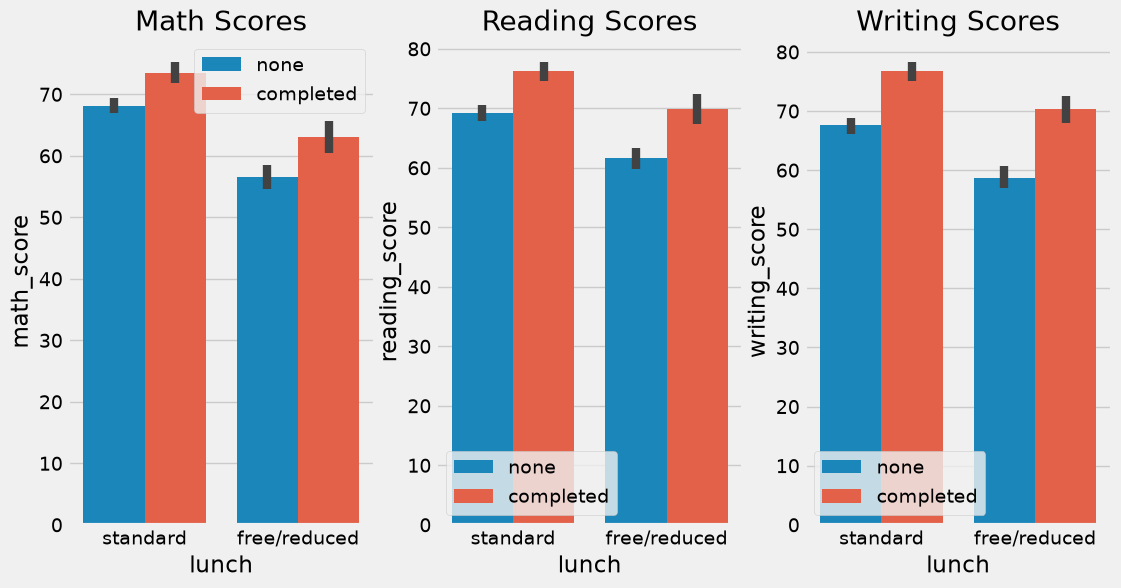

In [145]:
plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
sns.barplot (x=df['lunch'], y=df['math_score'], hue=df['test_preparation_course'])
plt.legend(loc='best') 
plt.title('Math Scores')


plt.subplot(1,3,2)
sns.barplot (x=df['lunch'], y=df['reading_score'], hue=df['test_preparation_course'])
plt.legend(loc='best') 
plt.title('Reading Scores')


plt.subplot(1,3,3)
sns.barplot (x=df['lunch'], y=df['writing_score'], hue=df['test_preparation_course'])
plt.legend(loc='best') 
plt.title('Writing Scores')
plt.show()

#### 4.4.6 CHECKING OUTLIERS

In [147]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total score', 'average'],
      dtype='str')

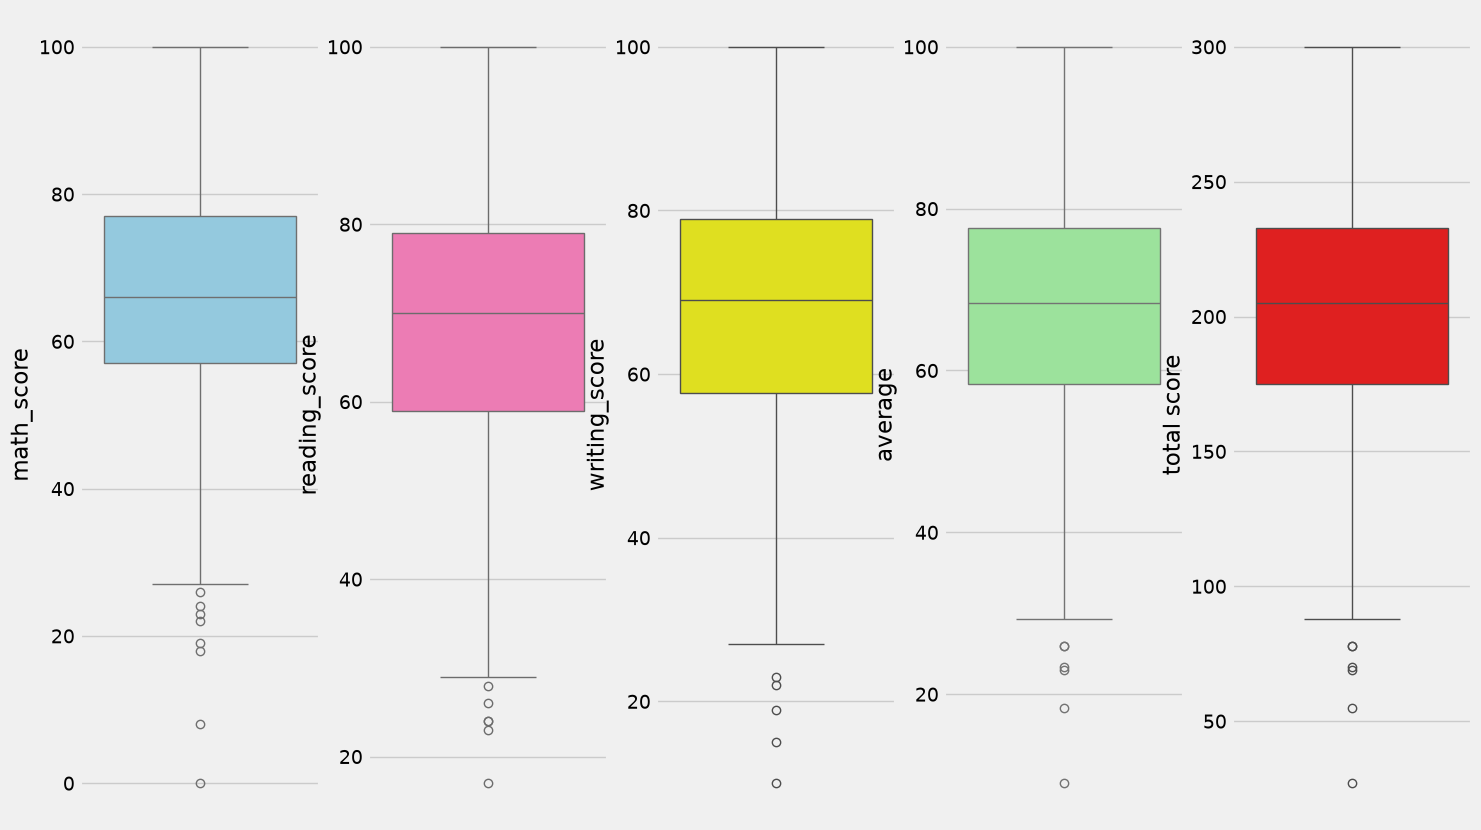

In [150]:
plt.subplots(1,5,figsize=(16,10))
plt.subplot(151)
sns.boxplot(df['math_score'],color='skyblue')
plt.subplot(152)
sns.boxplot(df['reading_score'],color='hotpink')
plt.subplot(153)
sns.boxplot(df['writing_score'],color='yellow')
plt.subplot(154)
sns.boxplot(df['average'],color='lightgreen')
plt.subplot(155)
sns.boxplot(df['total score'],color='red')
plt.show()

#### 4.4.7 MUTIVARIATE ANALYSIS USING PAIRPLOT

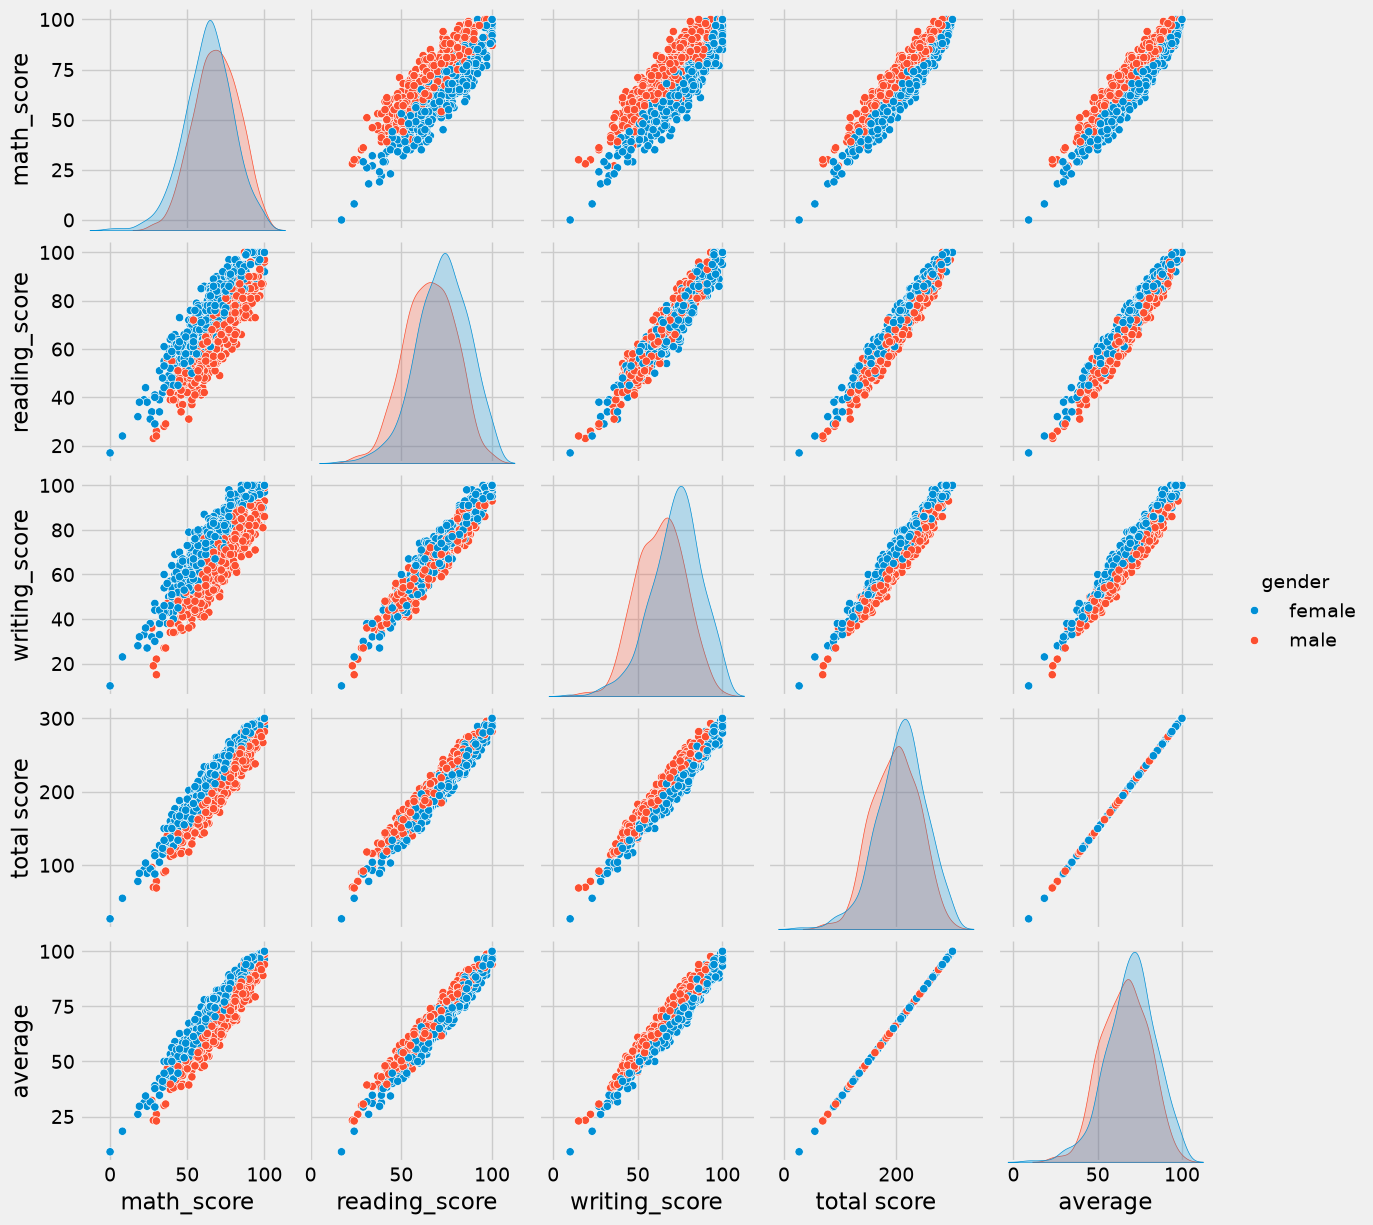

In [146]:
sns.pairplot(df,hue = 'gender')
plt.show()

##### Below Package could be used for automatic EDA generation 

In [5]:
from ydata_profiling import ProfileReport
profile = ProfileReport(df, title="Automated EDA Report", explorative=True)
profile.to_notebook_iframe()


ModuleNotFoundError: No module named 'pkg_resources'